NGC 6503: 11664 × 8748 pixels
Filter: g'; exposure: 120 s


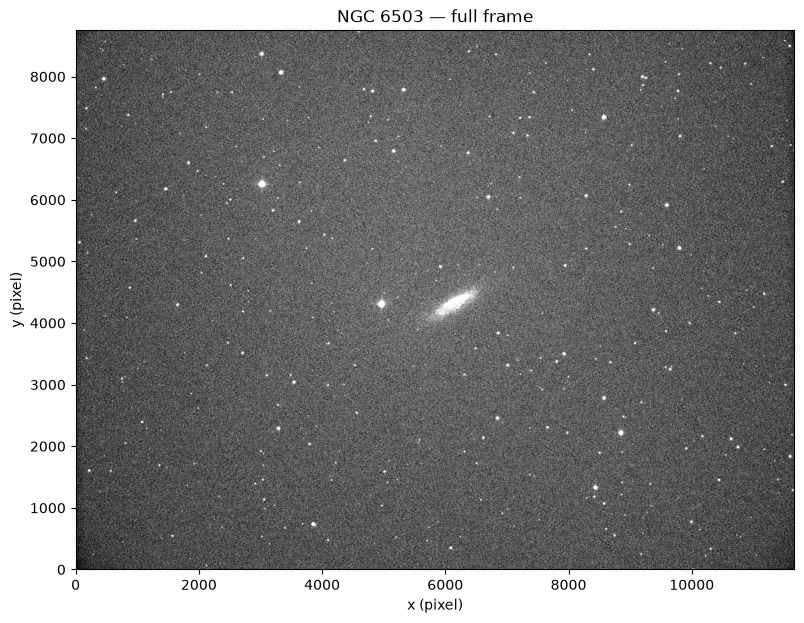

In [11]:
# Load the NGC 6503 g-band image (the observation folder is 2026-10-06).
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from matplotlib.colors import AsinhNorm

project_dir = Path.cwd() if Path("data").is_dir() else Path.cwd() / "project"
fits_path = project_dir / "data/big_void_galaxy/2026-10-06/NGC-6503_LIGHT_g'_1x1_120.000secs_00000099.fit"
with fits.open(fits_path) as hdul:
    image = hdul[0].data.copy()
    header = hdul[0].header.copy()

print(f"{header['OBJECT']}: {image.shape[1]} × {image.shape[0]} pixels")
print(f"Filter: {header['FILTER']}; exposure: {header['EXPTIME']:g} s")
# Subsample only the full-frame preview; retain the full image for the crop.
preview = image[::8, ::8]
vmin, vmax = np.percentile(preview, [1, 99.7])
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(preview, origin="lower", cmap="gray",
          norm=AsinhNorm(linear_width=(vmax - vmin) / 10, vmin=vmin, vmax=vmax),
          extent=(-0.5, image.shape[1] - 0.5, -0.5, image.shape[0] - 0.5))
ax.set(xlabel="x (pixel)", ylabel="y (pixel)", title=f"{header['OBJECT']} — full frame")
plt.show()


In [12]:
# Read the pointing coordinates recorded in the FITS header.
ra_text, dec_text = header["OBJCTRA"], header["OBJCTDEC"]
ra_h, ra_m, ra_s = map(float, ra_text.split())
dec_d, dec_m, dec_s = map(float, dec_text.split())
ra_deg = 15 * (ra_h + ra_m / 60 + ra_s / 3600)
dec_sign = -1 if dec_text.strip().startswith("-") else 1
dec_deg = dec_sign * (abs(dec_d) + dec_m / 60 + dec_s / 3600)
print(f"Object: {header['OBJECT']}")
print(f"RA (h m s): {ra_text}; Dec (deg arcmin arcsec): {dec_text}")
print(f"Decimal degrees: RA = {ra_deg:.6f}, Dec = {dec_deg:.6f}")
# OBJCTRA/OBJCTDEC describe the telescope pointing, not a measured galaxy center.
# This file has no celestial WCS, so pixels cannot be mapped to RA/Dec from it.


Object: NGC 6503
RA (h m s): 17 49 27.416; Dec (deg arcmin arcsec): +70 08 37.19
Decimal degrees: RA = 267.364233, Dec = 70.143664


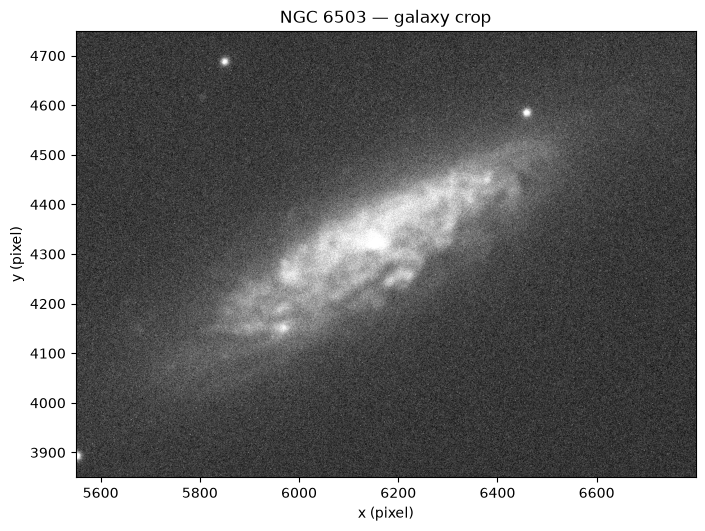

In [13]:
# Zoom into the galaxy using bounds chosen from the full-frame preview.
xmin, xmax = 5550, 6800
ymin, ymax = 3850, 4750
galaxy = image[ymin:ymax, xmin:xmax]
vmin, vmax = np.percentile(galaxy, [1, 99.7])
galaxy_norm = AsinhNorm(linear_width=(vmax - vmin) / 10, vmin=vmin, vmax=vmax)
extent = (xmin - 0.5, xmax - 0.5, ymin - 0.5, ymax - 0.5)
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(galaxy, origin="lower", cmap="gray", norm=galaxy_norm, extent=extent)
ax.set(xlabel="x (pixel)", ylabel="y (pixel)", title=f"{header['OBJECT']} — galaxy crop")
plt.show()


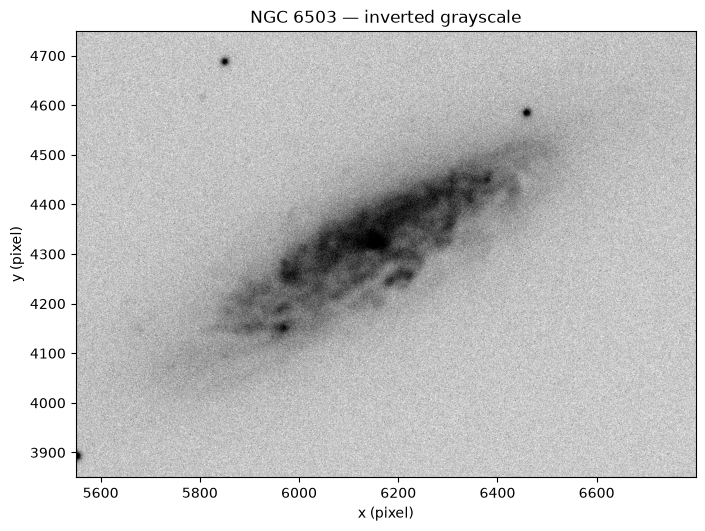

In [14]:
# Invert the display colors while preserving the image values and stretch.
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(galaxy, origin="lower", cmap="gray_r", norm=galaxy_norm, extent=extent)
ax.set(xlabel="x (pixel)", ylabel="y (pixel)", title=f"{header['OBJECT']} — inverted grayscale")
plt.show()


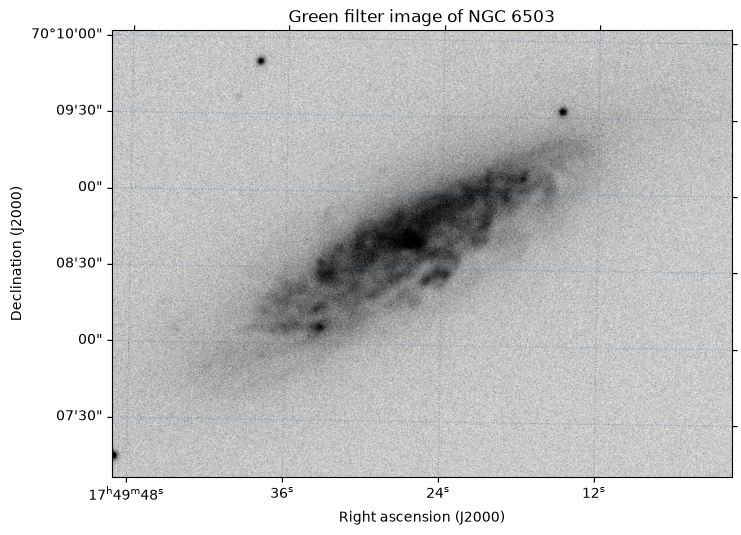

Crop center: RA = 267.356359 deg, Dec = 70.143341 deg


In [16]:
# Use the measured Astrometry.net solution for celestial coordinates.
from astropy.wcs import WCS

wcs_header = fits.getheader(project_dir / "ngc6503_g.wcs.fits")
image_wcs = WCS(wcs_header, naxis=2)
# Slice the WCS together with the image so crop pixels retain their sky positions.
galaxy_wcs = image_wcs[ymin:ymax, xmin:xmax]
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection=galaxy_wcs)
ax.imshow(galaxy, origin="lower", cmap="gray_r", norm=galaxy_norm)
ax.coords[0].set_axislabel("Right ascension (J2000)")
ax.coords[0].set_major_formatter("hh:mm:ss")
ax.coords[1].set_axislabel("Declination (J2000)")
ax.coords[1].set_major_formatter("dd:mm:ss")
ax.coords.grid(color="tab:blue", alpha=0.4, linestyle=":")
ax.set_title(f"Green filter image of {header['OBJECT']}")
plt.show()

center_ra, center_dec = galaxy_wcs.pixel_to_world_values(
    (galaxy.shape[1] - 1) / 2, (galaxy.shape[0] - 1) / 2)
print(f"Crop center: RA = {center_ra:.6f} deg, Dec = {center_dec:.6f} deg")
# Solution: 0.19473 arcsec/pixel; 38 catalog matches; RMS residual 0.29 arcsec.
